## АНАЛИЗ И ВЫЯВЛЕНИЕ ЗАКОНОМЕРНОСТЕЙ

In [1]:
# Импорт библиотек
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
# Загрузка данных
df = pd.read_csv('../data/raw-data/fmcg_sales_marketing_profitability_2023_2025.csv')
df.head() 

,Order_ID,Order_Date,Year,Quarter,Month,Month_Name,Region,Country,City,Sales_Person,...,Units_Sold,Unit_Price_USD,Discount_Pct,Gross_Sales_USD,Marketing_Spend_USD,COGS_USD,Logistics_Cost_USD,Net_Revenue_USD,Profit_USD,Profit_Margin_Pct
0,FMCG-2025-000001,2025-09-26,2025,Q3,9,September,Oceania,Australia,Perth,Ethan Cole,...,73,8.47,8.94,618.31,66.05,314.09,43.03,563.03,139.86,24.84
1,FMCG-2024-000002,2024-10-09,2024,Q4,10,October,Asia,India,Mumbai,Meera Nair,...,99,2.89,9.86,286.11,35.26,123.79,23.89,257.90,74.96,29.07
2,FMCG-2024-000003,2024-07-06,2024,Q3,7,July,North America,USA,Los Angeles,Nina Booker,...,361,5.96,15.32,2151.56,171.46,1011.60,107.02,1821.94,531.86,29.19
3,FMCG-2024-000004,2024-05-25,2024,Q2,5,May,Europe,France,Paris,Oliver Kent,...,603,3.80,18.00,2291.40,118.39,1133.66,85.20,1878.95,541.70,28.83
4,FMCG-2023-000005,2023-08-10,2023,Q3,8,August,Europe,France,Lyon,Lucas Bennett,...,113,3.18,12.46,359.34,34.82,157.70,23.02,314.57,99.03,31.48


In [126]:
# Изменение к тому же периоду прошлого года для каждого квартала и месяца
def yoy_table(keys):
    g = df.groupby(keys)[['Net_Revenue_USD', 'Profit_USD']].sum().reset_index()
    g['Margin'] = g['Profit_USD'] / g['Net_Revenue_USD'] * 100

    prev = g.copy()
    prev['Year'] += 1

    res = g.merge(prev, on=keys, suffixes=('', '_py'))
    res['revenue_yoy_%'] = (res['Net_Revenue_USD']/res['Net_Revenue_USD_py'] - 1) * 100
    res['profit_yoy_%'] = (res['Profit_USD']/res['Profit_USD_py'] - 1) * 100
    res['margin_yoy_pp'] = res['Margin'] - res['Margin_py']
    return res[keys + ['revenue_yoy_%', 'profit_yoy_%', 'margin_yoy_pp']].round(2)

quarters = yoy_table(['Year', 'Quarter'])
months = yoy_table(['Year', 'Month'])

print('Кварталы:')
display(quarters[['revenue_yoy_%', 'profit_yoy_%', 'margin_yoy_pp']].describe().loc[['min', 'std', 'mean', 'max']])
print('Месяцы:')
display(months[['revenue_yoy_%', 'profit_yoy_%', 'margin_yoy_pp']].describe().loc[['min', 'std', 'mean', 'max']])

Кварталы:


,revenue_yoy_%,profit_yoy_%,margin_yoy_pp
min,-2.33000,-3.950000,-0.430000
std,3.30726,4.668627,0.580515
mean,4.58000,6.127500,0.323750
max,9.13000,10.450000,1.090000


Месяцы:


,revenue_yoy_%,profit_yoy_%,margin_yoy_pp
min,-12.910000,-11.990000,-1.170000
std,8.982915,9.700878,0.859562
mean,4.708333,6.195833,0.309583
max,21.890000,23.020000,1.840000


In [108]:
df_date = df[['Order_Date', 'Year', 'Quarter', 'Month', 'Month_Name', 'Net_Revenue_USD', 'Profit_USD']].copy()

# Выручка по кварталам
df_quarter = df_date.groupby(['Year', 'Quarter'])[['Net_Revenue_USD', 'Profit_USD']].sum().reset_index()
df_quarter = df_quarter.sort_values(by=['Year', 'Quarter'])
df_quarter['Quarter_Year'] = df_quarter['Quarter'] + '-' + df_quarter['Year'].astype(str)

# Выручка по месяцам
df_month = df_date.groupby(['Year', 'Month', 'Month_Name'])[['Net_Revenue_USD', 'Profit_USD']].sum().reset_index()
df_month = df_month.sort_values(by=['Year', 'Month'])
df_month['Month_Year'] = df_month['Month_Name'] + '-' + df_month['Year'].astype(str)

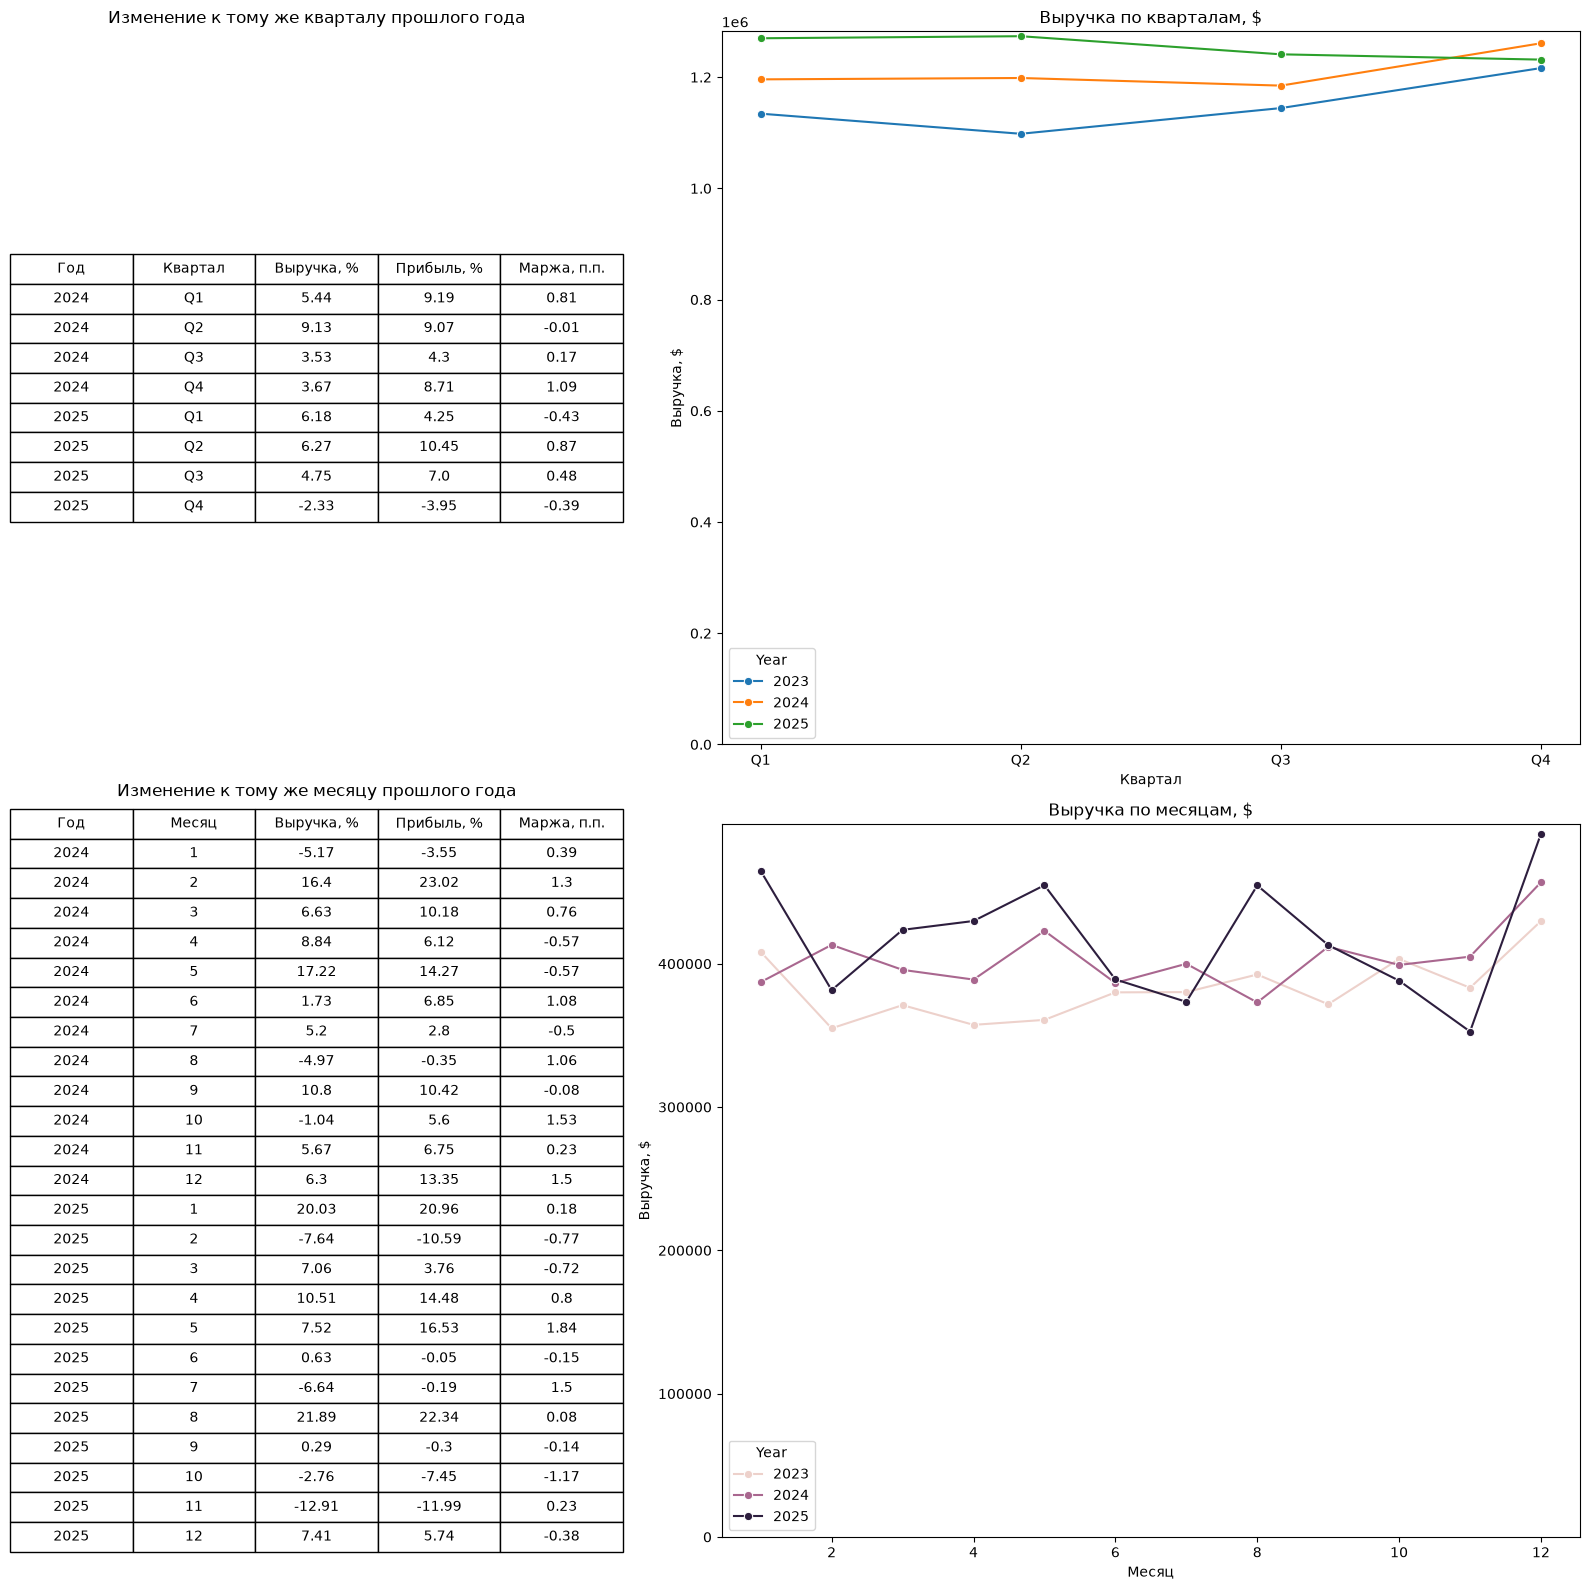

In [127]:
fig, ((ax_q, ax_g1), (ax_m, ax_g2)) = plt.subplots(
    2, 2, figsize=(16, 16), gridspec_kw={'width_ratios': [1, 1.4]}
)

# Левая часть: таблица изменений к прошлому году
ax_q.axis('off')
tbl = ax_q.table(
    cellText=quarters.values,
    colLabels=['Год', 'Квартал', 'Выручка, %', 'Прибыль, %', 'Маржа, п.п.'],
    loc='center',
    cellLoc='center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.4)
ax_q.set_title('Изменение к тому же кварталу прошлого года')

# Правая часть: выручка по кварталам
sns.lineplot(data=df_quarter, x='Quarter', y='Net_Revenue_USD', hue='Year', marker='o',  palette='tab10', ax=ax_g1)
ax_g1.set_ylim(bottom=0)
ax_g1.set_title('Выручка по кварталам, $')
ax_g1.set_xlabel('Квартал')
ax_g1.set_ylabel('Выручка, $')

# Левая часть: таблица изменений к прошлому году
ax_m.axis('off')
tb2 = ax_m.table(
    cellText=months.astype(str).values,
    colLabels=['Год', 'Месяц', 'Выручка, %', 'Прибыль, %', 'Маржа, п.п.'],
    loc='center',
    cellLoc='center',
)
tb2.auto_set_font_size(False)
tb2.set_fontsize(10)
tb2.scale(1, 1.4)
ax_m.set_title('Изменение к тому же месяцу прошлого года', pad=20)

# Правая часть: выручка по месяцам
sns.lineplot(data=df_month, x='Month', y='Net_Revenue_USD', hue='Year', marker='o', ax=ax_g2)
ax_g2.set_ylim(bottom=0)
ax_g2.set_title('Выручка по месяцам, $')
ax_g2.set_xlabel('Месяц')
ax_g2.set_ylabel('Выручка, $')

plt.tight_layout()
plt.show()

  
Снижение выручки в IV кв. 2025 (−2,33% к IV кв. 2024) существенно по направлению: это единственный квартал со снижением из 8, на 5,9 п.п. ниже самого слабого из предыдущих кварталов. В деньгах изменение небольшое: падение на 29,4 тыс. $ (0,6% годовой выручки, 17% годового прироста).

Также заметно снижение прибыли в IV кв. 2025 (-3,95%), она ниже на 8,2 п.п. самого слабого из предыдущих кварталов. В деньгах падение на 11,8 тыс. $ (1% годовой выручки, 25% годового прироста).

Изменение маржи в IV кв. (−0,39 п.п.) в пределах обычного разброса: в I кв. 2025 было −0,43 п.п.<br>
Месячные изменения слишком шумные (σ ≈ 9 п.п.) для выводов по одному месяцу. Внутри IV квартала снижение сосредоточено в ноябре (−12,9%)».

In [125]:
# Сводная таблица для проверки выручки по последним кварталам годов
q = df.pivot_table(
    index='Year',
    columns='Quarter',
    values='Net_Revenue_USD',
    aggfunc='sum',
)
q_vs = q[['Q3', 'Q4']].copy()
q_vs['Q3_vs_Q4'] = (q_vs['Q4'] / q_vs['Q3'] - 1) * 100
q_vs.round(2)

Quarter,Q3,Q4,Q3_vs_Q4
Year,,,
2023,1144405.04,1216355.53,6.29
2024,1184802.93,1260967.72,6.43
2025,1241094.47,1231567.18,-0.77


В двух прошлых годах IV квартал сезонно был сильнее III-его примерно на 6%, а в 2025 году это утверждение не сработало (-0,77%). Поэтому сравнение с этим кварталом прошлого года дало -2,33%: обычного сезонного роста не случилось. Выручка за IV квартал 2025 года почти равна выручке за III квартал, следовательно это не провал, а отсутствие роста.

*Примечание: конечно по результатам трех лет нельзя утверждать про сезонность, нужно больше исторических данных. Также иследования происходит в рамках учебного проекта и сезонность могла быть частью генератора цифр.*